Group 6 - Assigment 1: Linear Regression - House prices

- Benjamin Michel
- Ha Huynh Thu
- Naomi Hannoun
- Vitor Reis

# Element of Machine Learning For Business 

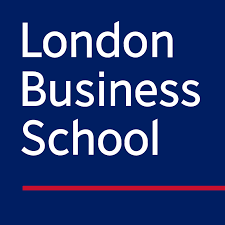

# Assignment 1

## Linear Regression - House prices

This first assignment has the scope to make you familiarize yourself with Python, apply what you have seen during the pre-course, work, and implement the first class of model we see during the course.

In this assignment, we want to **predict the sale price of a house** using its features. Besides the sale price, the dataset contains many features for each house (size, number of bathrooms, year of construction, etc.). 

To understand the relations that link the house features with its price, each group has to do the following: 

1. Select the target variable (Y) from the data - The Target name is **SalePrice**, and  select the following variables as predictors (X) from the Data: **GrLivArea**, **LotArea**, and **LotFrontage**.
2. Plot the scatter plot of each predictor (X) versus the target variable (Y) to see if there is a linear relation between the two variables.
3. Split the data into training and test sample
4. Estimate the parameters of the univariate regression using as predictor only the variable **LotArea**.
5. Use the prameters to fit the linear regression line and add it to the relevant scatter plot of point 3.
6. Compute the mean squared error and the R-squared of the univariate linear model using the test data.
7. Estimate the parameters of the multivariate regression using as predictor all the X selected at point 2, using only the training data.
8. Compute the mean squared error, and the R-squared of the multivariate linear model using the test data.
9. Which model has the lowest mean squared error and the better R-squared? Why?

In [1]:
#### Load the packages

# Basic packages everyone uses 
import pandas as pd
import numpy as np

# Analysing linear regression model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# To make graphs
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import the data using pandas
house_data = pd.read_csv("Data/House_price.csv", header = 0)
house_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
house_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

### Data Manipulation

In this first assignment, since we have not seen already how to perform a little of data manipulation, which includes: dummy conversion, missing elimination or substitution, outlier elimination etc... We will clean the data for you so you can start to work with a "cleaned" data matrix.

**Data Manipulation** will be showed in detail on the first tutorial of the course this Friday.


We modify the **house_data** as follow:

1. Eliminate all the object type data
2. Eliminate all the missings

In [4]:
# 1. Eliminate all the columns of type the object type data
house_data = house_data.select_dtypes(include=['int64', 'float64'])

# 2. Eliminate missing values
print('`house_data` containes %d missing values' %(house_data.isnull().sum().sum()))
house_data.dropna(inplace=True)
print("")

# 3. Check presence of missing
print('After the missing elimination, there are %d missing in the data.' %(house_data.isnull().sum().sum()))

`house_data` containes 348 missing values

After the missing elimination, there are 0 missing in the data.


In [5]:
# Another way of cleaning the dataset 
# house_data1 = house_data.drop(house_data.select_dtypes(include=['object']),axis=1)
# house_data1.info()
house_data.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,...,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000,1121.000000
mean,726.842105,56.146298,70.665477,10122.956289,6.212310,5.561106,1972.264942,1985.683318,108.487957,438.399643,...,92.610169,46.130241,21.844781,3.348796,16.100803,2.934880,23.429081,6.339875,2007.795718,185506.152542
std,420.769012,41.772684,24.266812,8129.302641,1.380822,1.068236,30.967730,21.025974,189.500966,468.385038,...,121.868623,64.390029,61.282083,29.772540,57.801829,40.222087,165.759816,2.687854,1.335043,82999.159004
min,1.000000,20.000000,21.000000,1300.000000,2.000000,2.000000,1880.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,35311.000000
25%,364.000000,20.000000,60.000000,7590.000000,5.000000,5.000000,1953.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,131000.000000
50%,725.000000,50.000000,70.000000,9416.000000,6.000000,5.000000,1974.000000,1995.000000,0.000000,374.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,164900.000000
75%,1091.000000,70.000000,80.000000,11361.000000,7.000000,6.000000,2003.000000,2005.000000,170.000000,702.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,219500.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,648.000000,2500.000000,12.000000,2010.000000,755000.000000


In [6]:
house_data.shape

(1121, 38)

In [7]:
house_data.columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')

### 1. Select the Target variable (Y) and the predictors (X).

In [8]:
X = house_data[['GrLivArea','LotArea','LotFrontage']]
Y = house_data[['SalePrice']]
Y

,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000
...,...
1455,175000
1456,210000
1457,266500
1458,142125


In [9]:
# I am selecting my data 
X_2 = house_data.loc[:,['GrLivArea','LotArea','LotFrontage']]
X_2

,GrLivArea,LotArea,LotFrontage
0,1710,8450,65.0
1,1262,9600,80.0
2,1786,11250,68.0
3,1717,9550,60.0
4,2198,14260,84.0
...,...,...,...
1455,1647,7917,62.0
1456,2073,13175,85.0
1457,2340,9042,66.0
1458,1078,9717,68.0


## 2\. Plot predictors vs target 

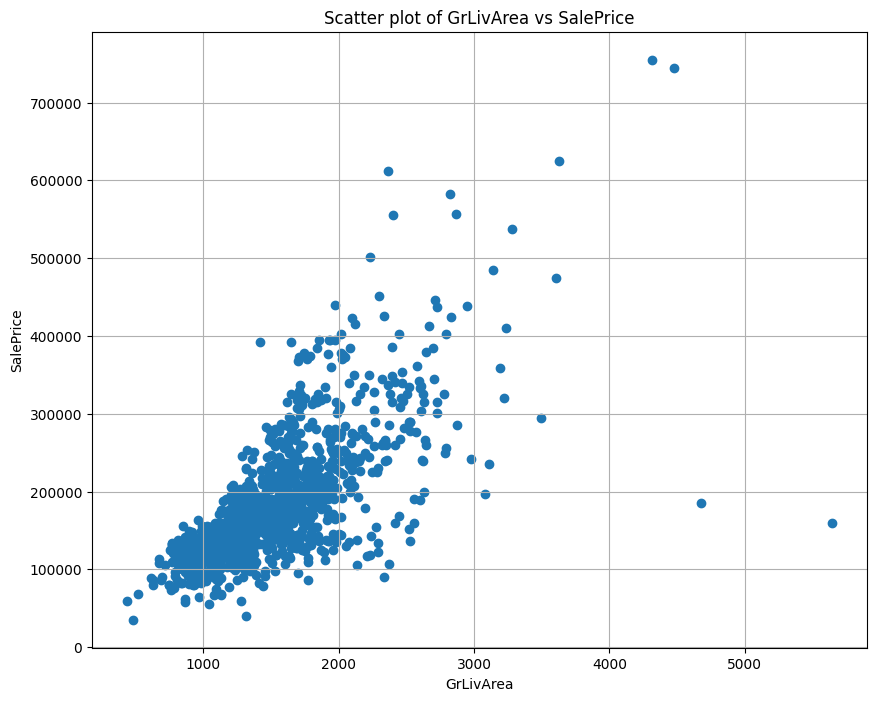

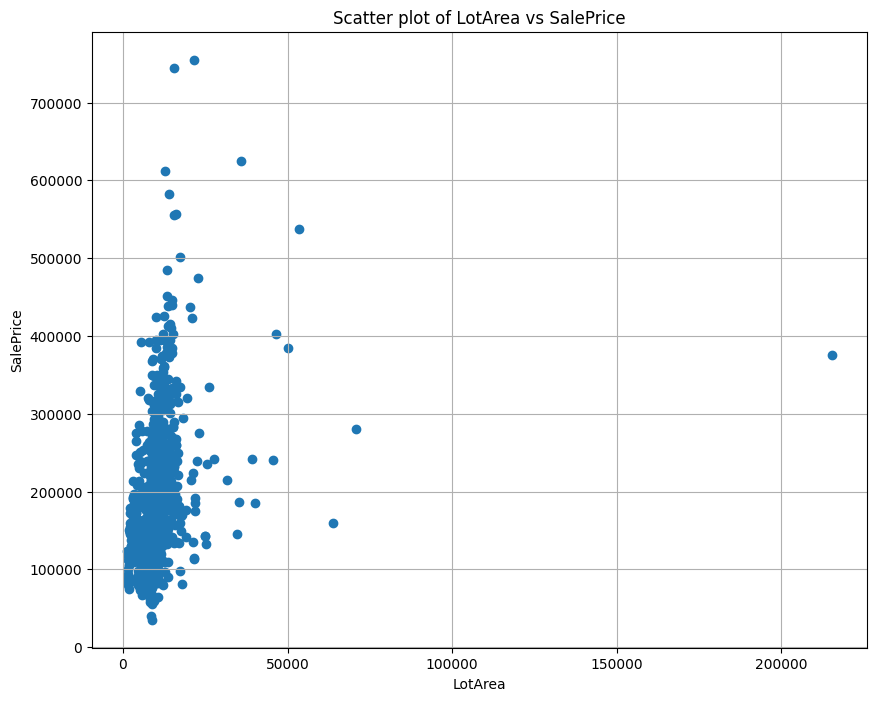

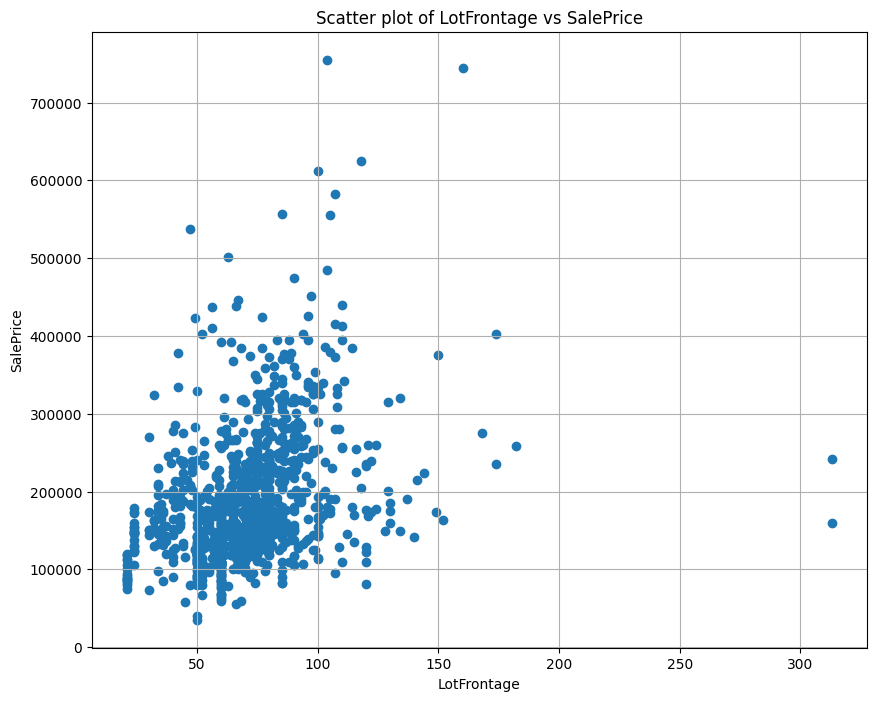

In [10]:
# Plotting 
for i in X.columns:
    plt.figure(figsize=(10,8))
    plt.scatter(X[i],Y)
    plt.title('Scatter plot of ' + i + ' vs SalePrice')
    plt.xlabel(i)
    plt.ylabel('SalePrice')
    plt.grid()
    plt.show()

In [11]:
X.columns

Index(['GrLivArea', 'LotArea', 'LotFrontage'], dtype='str')

### 3\. Split sample into train and test set 

In [12]:
x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size= 0.2, random_state = 8)

In [13]:
x_train[['LotArea']]

,LotArea
888,15865
952,7200
1241,9849
1204,10140
1258,9587
...,...
184,7438
1284,9638
181,7588
468,11428


### 4\. Estimate the parameters of the univariate regression using as predictor only the variable **LotArea**.

In [14]:
# Univariate regression using LotArea only
model_lotarea = LinearRegression()
model_lotarea.fit(x_train[['LotArea']], y_train)

print('Intercept:', model_lotarea.intercept_[0])
print('Coefficient for LotArea:', model_lotarea.coef_[0][0])

Intercept: 157183.7024709716
Coefficient for LotArea: 2.79172323974861


### 5\. Use the prameters to fit the linear regression line and add it to the relevant scatter plot of point 3.

c:\Users\vitor\Documents\LBS Classes\LBS Python Classes\.venv\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


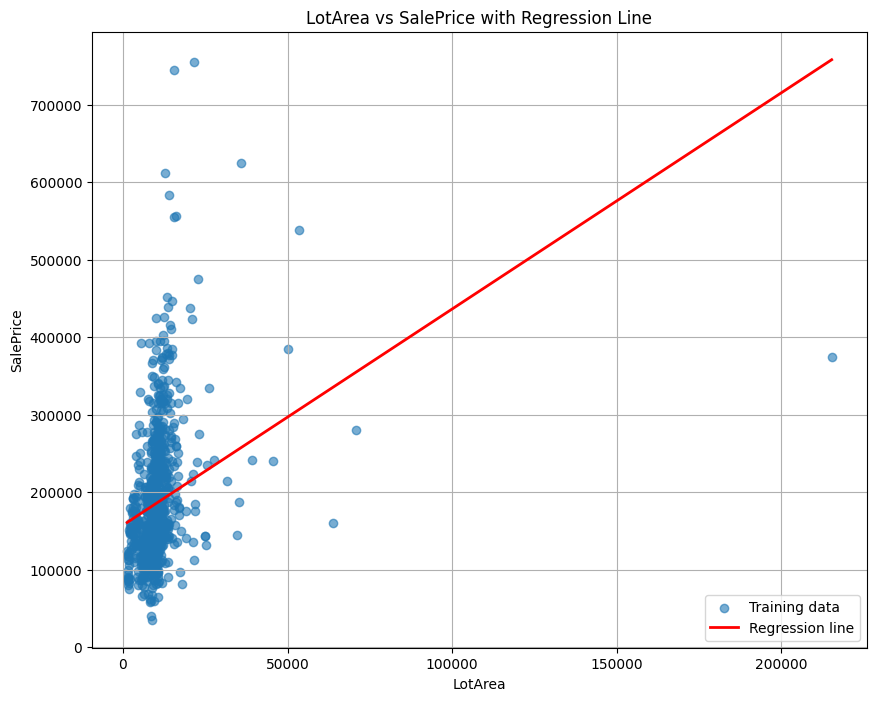

In [15]:
# Generate 100 evenly spaced LotArea values between min and max to draw a smooth regression line
lotarea_line = np.linspace(X['LotArea'].min(), X['LotArea'].max(), 100).reshape(-1, 1)
# Predict SalePrice for each of those LotArea values using the fitted model
saleprice_line = model_lotarea.predict(lotarea_line)

plt.figure(figsize=(10, 8))
plt.scatter(x_train['LotArea'], y_train, alpha=0.6, label='Training data')
plt.plot(lotarea_line, saleprice_line, color='red', linewidth=2, label='Regression line')
plt.title('LotArea vs SalePrice with Regression Line')
plt.xlabel('LotArea')
plt.ylabel('SalePrice')
plt.grid()
plt.legend()
plt.show()

### 6\. Compute the mean squared error and the R-squared of the univariate linear model using the test data.


In [16]:
# Evaluate the univariate model on the test data
y_pred_lotarea = model_lotarea.predict(x_test[['LotArea']])

mse_lotarea = mean_squared_error(y_test, y_pred_lotarea)
r2_lotarea = r2_score(y_test, y_pred_lotarea)

print('Univariate model MSE:', mse_lotarea)
print('Univariate model R-squared:', r2_lotarea)

Univariate model MSE: 5468797574.325345
Univariate model R-squared: 0.1092246312905879


### 7\. Estimate the parameters of the multivariate regression using as predictor all the X selected at point 2, using only the training data.


In [17]:
# Multivariate regression using all selected predictors
model_multi = LinearRegression()
model_multi.fit(x_train, y_train)

print('Intercept:', model_multi.intercept_[0])
print('Coefficients:')
for feature, coefficient in zip(X.columns, model_multi.coef_[0]):
    print(feature + ':', coefficient)

Intercept: 5968.821193833079
Coefficients:
GrLivArea: 108.62699891918763
LotArea: 0.8386240093409307
LotFrontage: 73.62783762870906


### 8\. Compute the mean squared error, and the R-squared of the multivariate linear model using the test data.


In [18]:
# Evaluate the multivariate model on the test data
y_pred_multi = model_multi.predict(x_test)

mse_multi = mean_squared_error(y_test, y_pred_multi)
r2_multi = r2_score(y_test, y_pred_multi)

print('Multivariate model MSE:', mse_multi)
print('Multivariate model R-squared:', r2_multi)

Multivariate model MSE: 3211396873.3653197
Multivariate model R-squared: 0.4769173305345561


### 9\. Which model has the lowest mean squared error and the better R-squared? Why?

In [20]:
# Compare the two models
print('Univariate model MSE:', mse_lotarea)
print('Univariate model R-squared:', r2_lotarea)
print('Multivariate model MSE:', mse_multi)
print('Multivariate model R-squared:', r2_multi)
print('')

if mse_multi < mse_lotarea and r2_multi > r2_lotarea:
    print('Answer: The multivariate model is better because it has the lowest MSE and the highest R-squared.')
    print('This happens because it uses more information: GrLivArea, LotArea, and LotFrontage, instead of only LotArea.')
elif mse_lotarea < mse_multi and r2_lotarea > r2_multi:
    print('Answer: The univariate model is better because it has the lowest MSE and the highest R-squared.')
else:
    print('Answer: The results are mixed, so compare both measures carefully.')
    print('In general, the better model should have lower MSE and higher R-squared.')

Univariate model MSE: 5468797574.325345
Univariate model R-squared: 0.1092246312905879
Multivariate model MSE: 3211396873.3653197
Multivariate model R-squared: 0.4769173305345561

Answer: The multivariate model is better because it has the lowest MSE and the highest R-squared.
This happens because it uses more information: GrLivArea, LotArea, and LotFrontage, instead of only LotArea.


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=d57f6231-c300-436f-90bb-8093ae7413fb' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>